[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/22_rnns_lstms.ipynb)

# 22 · RNNs & LSTMs: Networks With Memory

**Part 3 — Deep learning** · Notebook 22 of 27

Images have a fixed size and a spatial structure; CNNs exploit both. Text, speech, sensor readings, stock prices, and DNA are different: they come as **sequences**, their length varies, and **order matters**. "The dog bit the man" and "the man bit the dog" contain the same words. A model for sequences needs to read one element at a time and carry forward what it has seen so far.

A **recurrent neural network** (RNN) does exactly that. It keeps a hidden **state**, a vector that summarizes the past, and updates it at every step with the same small network: weight sharing across **time**, the way a CNN shares weights across **space** (CX lecture 13: *"one computation cell is shared"*). This notebook builds an RNN from scratch, shows why plain RNNs forget (the vanishing-gradient problem again, now across time steps), and builds the **LSTM**, whose additive "conveyor belt" memory fixes it. We finish with a character-level language model that learns to write fake Shakespeare, the direct ancestor of the GPT we'll build in notebook 25.

**What you'll learn**

1. Sequences: why order and variable length need a new architecture
2. The simple RNN cell, from scratch, and unrolling through time
3. Backpropagation through time (BPTT)
4. Why RNNs forget: vanishing and exploding gradients across time
5. Gradient clipping
6. **LSTM**: the conveyor belt and its three gates, built from scratch
7. A long-memory test: RNN vs. LSTM vs. GRU
8. Forecasting a time series
9. A character-level language model on Shakespeare
10. RNN shapes: one-to-many, many-to-one, many-to-many, and where they went next

*Course map: CX 4240 lecture 13 (recurrent neural networks: sequence prediction, variable-length inputs, the shared computation cell, simple RNN cells, BPTT, many-to-one / one-to-many / many-to-many uses, vanishing and exploding gradients, gradient clipping, the LSTM conveyor belt and forget/input/output gates, LSTM vs. ResNet, GRU) and the course cheat sheet's RNN/LSTM formulas.*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
import torch, torch.nn as nn, torch.nn.functional as F
import time, os, urllib.request
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} on {device}")
print("Ready ✓")

Setup complete ✓


PyTorch 2.14.1+cu130 on cpu
Ready ✓


---
## 1. Sequences

Three things make sequences different from the fixed-size inputs we've seen:

- **Variable length.** Reviews, sentences, and recordings all have different lengths. An MLP needs a fixed number of inputs.
- **Order matters.** A bag-of-words representation (notebook 14) loses it; "not good, bad" and "not bad, good" become identical.
- **Long-range dependencies.** The subject at the start of a long sentence determines the verb form at its end.

A sliding window (feed the last $k$ elements to an MLP) handles some of this, but it forgets everything older than $k$ steps and needs separate weights for each position in the window. The RNN's answer: read one element at a time and keep a running summary.

---
## 2. The simple RNN cell

At each time step $t$, the cell combines the current input $x_t$ with the previous state $h_{t-1}$:

$$h_t = \tanh\big(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h\big), \qquad y_t = W_{hy}\,h_t + b_y.$$

The **same** weights $W_{xh}, W_{hh}, W_{hy}$ are used at every step. Drawn "rolled up", it's one cell with a loop; **unrolled** over a sequence of length $T$, it's a $T$-layer deep network whose layers all share weights. Let's write it in NumPy and check it against PyTorch's `nn.RNN`:

In [2]:
def rnn_forward(X, Wxh, Whh, bh, h0=None):
    """X: (T, d_in). Returns all hidden states H: (T, d_h)."""
    h = np.zeros(Whh.shape[0]) if h0 is None else h0; H = []
    for x_t in X:                                      # one step at a time, same weights every step
        h = np.tanh(Wxh @ x_t + Whh @ h + bh); H.append(h)
    return np.array(H)

torch.manual_seed(0)
rnn_t = nn.RNN(input_size=3, hidden_size=4, batch_first=True)
Wxh = rnn_t.weight_ih_l0.detach().numpy(); Whh = rnn_t.weight_hh_l0.detach().numpy()
bh = (rnn_t.bias_ih_l0 + rnn_t.bias_hh_l0).detach().numpy()     # PyTorch keeps two bias vectors; their sum is our b_h
X_seq = np.random.default_rng(0).normal(size=(6, 3))
ours = rnn_forward(X_seq, Wxh, Whh, bh)
theirs = rnn_t(torch.tensor(X_seq, dtype=torch.float32)[None])[0][0].detach().numpy()
print("hidden states over 6 steps (ours):\n", ours.round(4))
print(f"max difference from nn.RNN: {np.abs(ours - theirs).max():.1e}")
print(f"parameters: {sum(p.numel() for p in rnn_t.parameters())}, the same for a sequence of length 6 or 6,000")

hidden states over 6 steps (ours):
 [[-0.7344 -0.2837 -0.5555 -0.0625]
 [-0.3572 -0.2656 -0.7578 -0.1541]
 [ 0.3021 -0.7501 -0.2961 -0.1922]
 [-0.5762  0.2082 -0.7927 -0.2189]
 [ 0.1872  0.5641 -0.5162 -0.3699]
 [-0.6797  0.411  -0.5048 -0.0671]]
max difference from nn.RNN: 4.0e-08
parameters: 36, the same for a sequence of length 6 or 6,000


The parameter count doesn't depend on the sequence length: the network handles any length with the same weights.

### What the hidden state remembers

A first task: a stream of random digits 0–9, and at each step, output the **sum of the last three digits**. The answer depends on inputs the network saw up to two steps ago, so it must store them in its state. Train a small RNN and look at its predictions:

test RMSE: 0.10 (on sums ranging from 0 to 27)


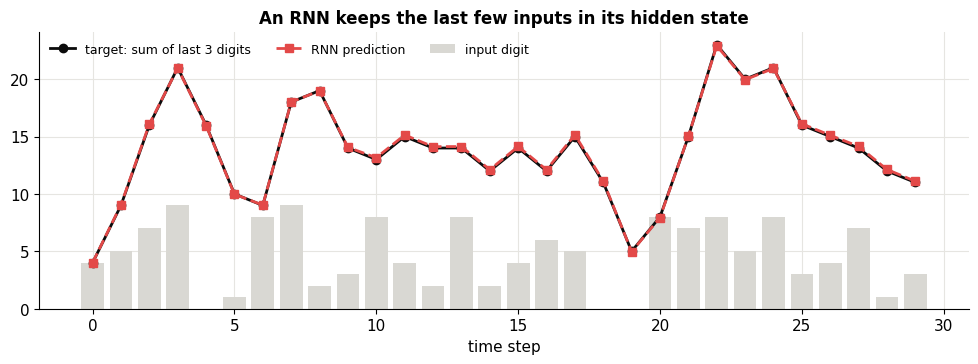

In [3]:
def make_sum3(n, T=30, seed=0):
    r = np.random.default_rng(seed); X = r.integers(0, 10, (n, T)).astype(np.float32)
    Y = X.copy(); Y[:, 1:] += X[:, :-1]; Y[:, 2:] += X[:, :-2]
    return torch.tensor(X[..., None] / 9), torch.tensor(Y[..., None] / 27)   # scale inputs and targets to [0, 1]

class SeqRegressor(nn.Module):
    def __init__(self, cell="rnn", hidden=32):
        super().__init__()
        self.rnn = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell](1, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x): return self.out(self.rnn(x)[0])           # a prediction at every step (many-to-many)

Xs3, Ys3 = make_sum3(2000); Xs3_te, Ys3_te = make_sum3(200, seed=1)
torch.manual_seed(0); m3 = SeqRegressor("rnn"); opt = torch.optim.Adam(m3.parameters(), lr=3e-3)
for step in range(1500):
    idx = torch.randint(0, len(Xs3), (64,)); loss = F.mse_loss(m3(Xs3[idx]), Ys3[idx])
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad(): pred = m3(Xs3_te)
rmse = ((pred - Ys3_te) ** 2).mean().sqrt().item() * 27
print(f"test RMSE: {rmse:.2f} (on sums ranging from 0 to 27)")
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(range(30), Xs3_te[0, :, 0] * 9, color=C["light"], label="input digit")
ax.plot(range(30), Ys3_te[0, :, 0] * 27, "o-", color=C["ink"], label="target: sum of last 3 digits")
ax.plot(range(30), pred[0, :, 0] * 27, "s--", color=C["red"], label="RNN prediction")
ax.set(xlabel="time step", title="An RNN keeps the last few inputs in its hidden state"); ax.legend(ncol=3, fontsize=9); plt.show()

---
> 🚧 **This notebook is being written section by section.** The sections above are complete and run top to bottom; more are on the way.